# 03 · Decision Tree (from scratch)

Implementation: `src/decision_tree.py`. We investigate:
1. **maximum depth** (with both splitting criteria, Gini and entropy)
2. **minimum samples in a leaf**
3. **minimum samples required to split a node**
4. **threshold resolution** (`n_bins`, a design choice of our implementation)

For each, we record **training** and **validation** accuracy: the gap between them is how we
diagnose under- vs over-fitting.

Preprocessing is irrelevant for trees: a threshold split works the same on any
order-preserving rescaling of a feature, so we use the raw features.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.common import *
from src.plotting import *
from src.decision_tree import DecisionTreeClassifier
set_seed()

splits = {t: get_split(t) for t in ("image", "sentiment")}

## 1 · Maximum depth × criterion

Shortcut: growing a tree is greedy and top-down, so a tree trained with `max_depth=d` is
exactly the top `d` levels of a fully grown tree. We grow one full tree per criterion and read
off every depth with `predict(X, max_depth=d)` instead of retraining. (We checked that this gives
identical predictions to separately trained trees; the cell below re-checks it once.)

In [2]:
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, None]
rows, full_trees = [], {}
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for crit in ("gini", "entropy"):
        with Timer() as t:
            tree = DecisionTreeClassifier(criterion=crit).fit(Xtr, ytr, N_CLASSES[task])
        full_trees[(task, crit)] = tree
        print(f"{task:9s} {crit:8s} full tree: depth {tree.depth}, {tree.n_leaves} leaves, {t.seconds:.1f}s")
        for d in DEPTHS:
            rows.append(dict(task=task, criterion=crit, max_depth=d if d is not None else tree.depth,
                             unlimited=d is None,
                             train_acc=accuracy(ytr, tree.predict(Xtr, max_depth=d)),
                             val_acc=accuracy(yva, tree.predict(Xva, max_depth=d))))
depth_results = pd.DataFrame(rows)
save_table(depth_results, "dt_depth_sweep")

# sanity check of the shortcut
Xtr, ytr, Xva, yva = splits["sentiment"]
t6 = DecisionTreeClassifier(max_depth=6).fit(Xtr, ytr)
print("shortcut identical to retraining (depth 6):",
      np.array_equal(t6.predict(Xva), full_trees[("sentiment", "gini")].predict(Xva, max_depth=6)))

image     gini     full tree: depth 92, 9453 leaves, 21.8s


image     entropy  full tree: depth 48, 9664 leaves, 20.7s


sentiment gini     full tree: depth 24, 1491 leaves, 3.0s


sentiment entropy  full tree: depth 17, 1309 leaves, 3.4s


shortcut identical to retraining (depth 6): True


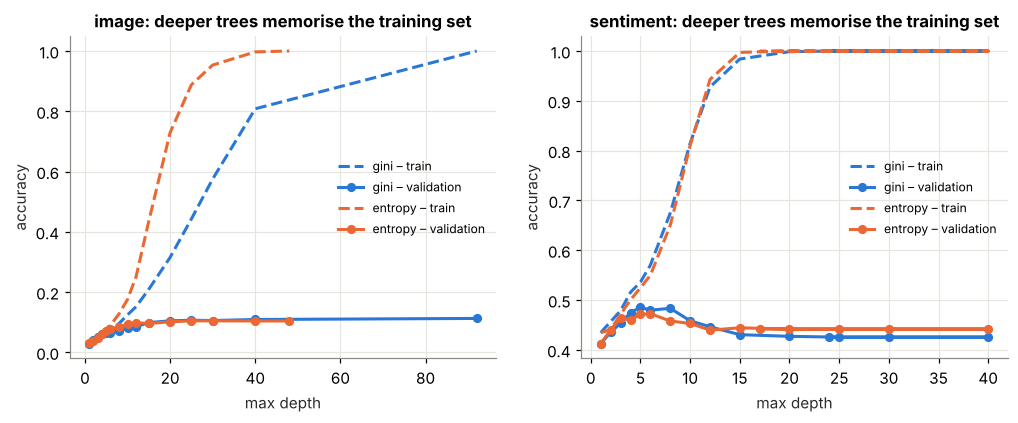

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    for j, crit in enumerate(("gini", "entropy")):
        r = depth_results[(depth_results.task == task) & (depth_results.criterion == crit)].drop_duplicates("max_depth")
        ax.plot(r.max_depth, r.train_acc, color=PALETTE[j], linestyle="--", label=f"{crit} – train")
        ax.plot(r.max_depth, r.val_acc, color=PALETTE[j], marker="o", label=f"{crit} – validation")
    ax.set_xlabel("max depth"); ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: deeper trees memorise the training set")
    ax.legend(fontsize=8)
savefig(fig, "03_dt_depth"); plt.show()

In [4]:
for task in ("image", "sentiment"):
    r = depth_results[depth_results.task == task]
    b = r.loc[r.val_acc.idxmax()]
    print(f"{task}: best depth {int(b.max_depth)} ({b.criterion}) -> train {b.train_acc:.3f}, val {b.val_acc:.3f}")
    print(depth_results[(depth_results.task == task) & (depth_results.criterion == b.criterion)]
          [["max_depth", "train_acc", "val_acc"]].drop_duplicates("max_depth").round(3).to_string(index=False))

image: best depth 92 (gini) -> train 1.000, val 0.113
 max_depth  train_acc  val_acc
         1      0.030    0.029
         2      0.040    0.041
         3      0.048    0.051
         4      0.058    0.060
         5      0.065    0.063
         6      0.072    0.063
         8      0.096    0.071
        10      0.125    0.080
        12      0.151    0.085
        15      0.209    0.099
        20      0.315    0.104
        25      0.443    0.107
        30      0.575    0.106
        40      0.808    0.109
        92      1.000    0.112
sentiment: best depth 5 (gini) -> train 0.536, val 0.485
 max_depth  train_acc  val_acc
         1      0.434    0.412
         2      0.457    0.435
         3      0.479    0.454
         4      0.516    0.475
         5      0.536    0.485
         6      0.570    0.480
         8      0.675    0.483
        10      0.814    0.458
        12      0.928    0.446
        15      0.984    0.430
        20      0.999    0.427
        25      1.000

**Reading the depth curves.**
* **Sentiment** shows the textbook pattern. Depth 1–3 **underfits**: training and validation
  accuracy are both low. Validation peaks around depth 5 (≈ 48.5%). Beyond depth 8, training accuracy
  races to 100% while validation *drops* to ≈ 42.5%: the tree is memorising noise (**overfitting**).
* **Images** are different. Training accuracy reaches 100%, but validation only creeps up to ≈ 11%
  (chance is 2%), so the tree **overfits massively at every depth**. Deeper never hurts validation
  here, because every split adds a sliver of signal. The real problem: each split asks about
  *one* visual word, and a single visual word is weak evidence among 50 classes. The tree runs out
  of samples (320 per class) long before it can combine enough of them.
* **Gini vs entropy** make little difference: best validation 48.5% vs 47.3% (sentiment) and 11.3% vs
  10.5% (image), within noise. Entropy builds shallower full trees (depth 17 vs 24, 48 vs 92).

## 2 · Minimum samples per leaf and per split
These stop the tree from creating tiny leaves that just memorise a few training points.
We use each task's best criterion with unlimited depth, so only the parameter being studied limits growth.

In [5]:
best_crit = {t: depth_results[depth_results.task == t].sort_values("val_acc").iloc[-1].criterion for t in splits}
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for param, values in (("min_samples_leaf", [1, 2, 5, 10, 20, 50, 100]),
                          ("min_samples_split", [2, 10, 20, 50, 100, 200])):
        for v in values:
            with Timer() as t:
                tree = DecisionTreeClassifier(criterion=best_crit[task], **{param: v}).fit(Xtr, ytr, N_CLASSES[task])
            rows.append(dict(task=task, param=param, value=v, depth=tree.depth, leaves=tree.n_leaves,
                             train_acc=accuracy(ytr, tree.predict(Xtr)), val_acc=accuracy(yva, tree.predict(Xva)),
                             fit_s=round(t.seconds, 1)))
        print(task, param, "done")
min_results = pd.DataFrame(rows)
save_table(min_results, "dt_min_samples_sweep")
min_results.round(3)

image min_samples_leaf done


image min_samples_split done


sentiment min_samples_leaf done


sentiment min_samples_split done


,task,param,value,depth,leaves,train_acc,val_acc,fit_s
0,image,min_samples_leaf,1,92,9453,1.000,0.112,21.9
1,image,min_samples_leaf,2,88,6149,0.761,0.113,19.1
2,image,min_samples_leaf,5,71,2559,0.494,0.106,12.7
3,image,min_samples_leaf,10,60,1251,0.346,0.110,8.6
4,image,min_samples_leaf,20,49,612,0.252,0.110,5.9
5,image,min_samples_leaf,50,42,236,0.173,0.119,3.6
6,image,min_samples_leaf,100,33,119,0.143,0.112,2.4
7,image,min_samples_split,2,92,9453,1.000,0.112,22.0
8,image,min_samples_split,10,85,3666,0.619,0.112,17.6
9,image,min_samples_split,20,81,2379,0.499,0.115,15.2


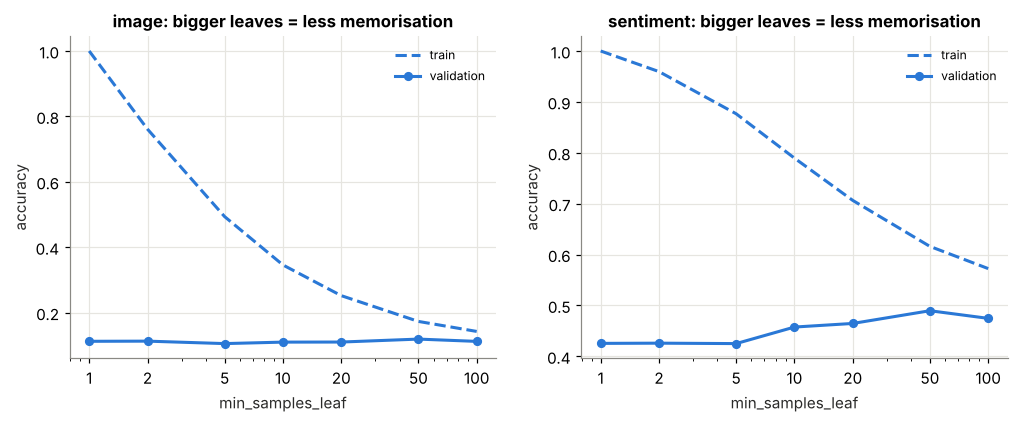

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    r = min_results[(min_results.task == task) & (min_results.param == "min_samples_leaf")]
    ax.plot(r.value, r.train_acc, color=PALETTE[0], linestyle="--", label="train")
    ax.plot(r.value, r.val_acc, color=PALETTE[0], marker="o", label="validation")
    ax.set_xscale("log"); ax.set_xticks(r.value); ax.set_xticklabels(r.value)
    ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: bigger leaves = less memorisation")
    ax.legend(fontsize=8)
savefig(fig, "03_dt_min_samples_leaf"); plt.show()

Requiring bigger leaves is another way to stop memorisation. For **sentiment**, validation accuracy
rises from 42.5% (leaves of 1) to 49.0% (leaves of ≥ 50) as training accuracy falls from 100% to 62%:
less overfitting, better generalisation. `min_samples_split` has a similar but weaker effect. For
**images**, validation stays between 10.6% and 11.9% whatever we do: a single tree is simply the
wrong tool for these features.

## 3 · Combining depth with min_samples_leaf
A small grid around the best values from the one-at-a-time sweeps.

In [7]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for leaf in (1, 5, 20, 50):
        tree = DecisionTreeClassifier(criterion=best_crit[task], min_samples_leaf=leaf).fit(Xtr, ytr, N_CLASSES[task])
        for d in (4, 6, 8, 10, 12, 15, 20, None):
            rows.append(dict(task=task, criterion=best_crit[task], min_samples_leaf=leaf,
                             max_depth=d if d is not None else -1,
                             train_acc=accuracy(ytr, tree.predict(Xtr, max_depth=d)),
                             val_acc=accuracy(yva, tree.predict(Xva, max_depth=d))))
grid = pd.DataFrame(rows)
save_table(grid, "dt_grid")
for task in splits:
    print(task)
    print(grid[grid.task == task].pivot(index="max_depth", columns="min_samples_leaf", values="val_acc").round(3))

image
min_samples_leaf     1      5      20     50
max_depth                                   
-1                0.112  0.106  0.110  0.119
 4                0.060  0.060  0.058  0.059
 6                0.063  0.062  0.061  0.064
 8                0.071  0.072  0.074  0.076
 10               0.080  0.080  0.085  0.086
 12               0.085  0.088  0.091  0.094
 15               0.099  0.100  0.102  0.104
 20               0.104  0.108  0.107  0.112
sentiment
min_samples_leaf     1      5      20     50
max_depth                                   
-1                0.425  0.425  0.465  0.490
 4                0.475  0.475  0.475  0.475
 6                0.480  0.480  0.479  0.483
 8                0.483  0.481  0.480  0.482
 10               0.458  0.455  0.462  0.490
 12               0.446  0.445  0.465  0.490
 15               0.430  0.428  0.465  0.490
 20               0.427  0.425  0.465  0.490


## 4 · Threshold resolution (`n_bins`)
Our tree considers up to `n_bins − 1` quantile thresholds per feature instead of every distinct value.

In [8]:
best_cfg = {}
for task in splits:
    g = grid[grid.task == task].sort_values("val_acc", ascending=False).iloc[0]
    best_cfg[task] = dict(criterion=g.criterion, min_samples_leaf=int(g.min_samples_leaf),
                          max_depth=None if g.max_depth == -1 else int(g.max_depth))
    print(task, best_cfg[task], "val_acc %.4f" % g.val_acc)

rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for nb in (8, 16, 32, 64, 128):
        with Timer() as t:
            tree = DecisionTreeClassifier(n_bins=nb, **best_cfg[task]).fit(Xtr, ytr, N_CLASSES[task])
        rows.append(dict(task=task, n_bins=nb, train_acc=accuracy(ytr, tree.predict(Xtr)),
                         val_acc=accuracy(yva, tree.predict(Xva)), fit_s=round(t.seconds, 1)))
bins_results = pd.DataFrame(rows)
save_table(bins_results, "dt_bins_sweep")
bins_results.round(3)

image {'criterion': 'gini', 'min_samples_leaf': 50, 'max_depth': None} val_acc 0.1192
sentiment {'criterion': 'gini', 'min_samples_leaf': 50, 'max_depth': None} val_acc 0.4896


,task,n_bins,train_acc,val_acc,fit_s
0,image,8,0.169,0.106,1.6
1,image,16,0.172,0.114,2.2
2,image,32,0.173,0.119,3.5
3,image,64,0.184,0.118,6.3
4,image,128,0.189,0.117,11.3
5,sentiment,8,0.606,0.477,1.1
6,sentiment,16,0.608,0.466,1.3
7,sentiment,32,0.616,0.490,1.5
8,sentiment,64,0.618,0.489,1.7
9,sentiment,128,0.623,0.478,2.2


## Final Decision Tree per task: save validation predictions, timings, top features

In [9]:
summary = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    with Timer() as t_fit:
        tree = DecisionTreeClassifier(**best_cfg[task]).fit(Xtr, ytr, N_CLASSES[task])
    with Timer() as t_pred:
        proba = tree.predict_proba(Xva)
    pred = proba.argmax(1)
    info = dict(model="Decision Tree", config=best_cfg[task], val_acc=accuracy(yva, pred),
                train_acc=accuracy(ytr, tree.predict(Xtr)), depth=tree.depth, leaves=tree.n_leaves,
                fit_seconds=t_fit.seconds, predict_seconds=t_pred.seconds)
    save_val_predictions(task, "dt", pred, proba, info)
    top = np.argsort(tree.feature_importances_)[::-1][:5]
    summary.append(dict(task=task, **best_cfg[task], depth=tree.depth, leaves=tree.n_leaves,
                        train_acc=round(info["train_acc"], 4), val_acc=round(info["val_acc"], 4),
                        fit_s=round(t_fit.seconds, 1),
                        top_features=", ".join(f"f{j} ({tree.feature_importances_[j]:.3f})" for j in top)))
pd.DataFrame(summary)

,task,criterion,min_samples_leaf,max_depth,depth,leaves,train_acc,val_acc,fit_s,top_features
0,image,gini,50,None,42,236,0.1733,0.1192,3.8,"f230 (0.069), f91 (0.050), f405 (0.047), f69 (..."
1,sentiment,gini,50,None,13,144,0.6160,0.4896,1.5,"f42 (0.127), f594 (0.091), f2 (0.051), f461 (0..."
